# 0. Goals 03_Exploratory_Data_Analysis

Q1 : Dimanakah rentang transaksi yang memiliki fraud rate terbesar? \
H1 : Pecah jadi beberapa bucket dan hitung masing masing fraud rate pada tiap bucket
\
\
Q2 : Apakah ada pola selisih waktu saat terjadi fraud only? \
H2 : filter data fraud only, sorted by time, buat selisih waktu antar fraud ke n dengan fraud ke n+1
\
\
Q4 : Apakah ada pola selisih waktu antara fraud dengan baris sebelumnya? \
H4 : Filter tiap 2 baris yang memiliki pola non-fraud & fraud, lalu cek selisih waktu nya ada pola atau ngga?
\
\
Q4.1 : Jika Q4 valid apakah pola ini valid, apakah ini juga didukung dengan kondisi yang non fraud? \
H4.1 : Filter tiap 2 baris yang memiliki pola non-fraud, cek pola serupa yang terjadi pada transaksi non fraud
\
\
Q5 : Apakah ada pola selisih Amount antara fraud dengan baris sebelumnya? \
H5 : Filter tiap 2 baris yang memiliki pola non-fraud & fraud, lalu cek selisih Amount nya ada pola atau ngga?
\
\
Q6 : Untuk tiap feature yang dianggap important, bagaimana distribusi kasus fraud di rentang outlier vs non outlier? \
H6 : Hasil dari feature Importance V1, ambil feature yang penting, bucketing outlier vs non outlier, cek distribusi fraud ny

# 1. RESULT EDA

Q = Pertanyaan ; A = Jawaban Data

Q1 : Dimanakah rentang transaksi yang memiliki fraud rate terbesar? \
A1 : Ada di bucket 1 dengan rentang transaksi 0 - 260. Dibuat Feature Engineering bucket untuk mengelompokkan kategori transaksi apakah transaksi kecil, menengah, atau besar.
\
\
Q4 : Apakah ada pola selisih waktu antara fraud dengan baris sebelumnya? \
A4 : Ada, banyaknya fraud terjadi di selisih rentang waktu 0-15 setelah transaksi sebelumnya. Pada rentang ini juga paling banyak transaksi non - fraud terjadi
\
\
Q8 : Untuk tiap feature yang dianggap important, bagaimana distribusi kasus fraud di rentang outlier vs non outlier? \
H8 : Tidak terdapat pola tertentu, akan tetapi tetap dibuat bucket pemisah outlier dan non outlier sebagai eksperimen selanjutnya dengan asumsi akan meningkatkan performa model

# Import Library & Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import joblib

In [2]:
path_data = r'..\Data\result\02_Data_Cleaning.csv'

In [3]:
df_fraud_eda = pd.read_csv(path_data)

In [4]:
# Untuk menghindari Label atau Data Leakage, maka proses Exploratory akan dipisahkan untuk train - test akhir diawal dengan rasio 90:10. 
# Sejalan dengan kali ini ditujukan untuk Predictive Analysis bukan Descriptive Analysis

df_fraud_eda = df_fraud_eda.iloc[:round(df_fraud_eda.shape[0]*0.9), :]
df_fraud_eda_test = df_fraud_eda.iloc[round(df_fraud_eda.shape[0]*0.9):, :]

In [5]:
df_fraud_eda_test.to_csv(r'..\Data\result\03_Exploratory_Data_Analysis_Test.csv', index=False)

In [6]:
df_fraud_eda.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
df_fraud_eda.shape

(255353, 31)

array([    0.    ,   196.5653,   393.1306,   589.6959,   786.2612,
         982.8265,  1179.3918,  1375.9571,  1572.5224,  1769.0877,
        1965.653 ,  2162.2183,  2358.7836,  2555.3489,  2751.9142,
        2948.4795,  3145.0448,  3341.6101,  3538.1754,  3734.7407,
        3931.306 ,  4127.8713,  4324.4366,  4521.0019,  4717.5672,
        4914.1325,  5110.6978,  5307.2631,  5503.8284,  5700.3937,
        5896.959 ,  6093.5243,  6290.0896,  6486.6549,  6683.2202,
        6879.7855,  7076.3508,  7272.9161,  7469.4814,  7666.0467,
        7862.612 ,  8059.1773,  8255.7426,  8452.3079,  8648.8732,
        8845.4385,  9042.0038,  9238.5691,  9435.1344,  9631.6997,
        9828.265 , 10024.8303, 10221.3956, 10417.9609, 10614.5262,
       10811.0915, 11007.6568, 11204.2221, 11400.7874, 11597.3527,
       11793.918 , 11990.4833, 12187.0486, 12383.6139, 12580.1792,
       12776.7445, 12973.3098, 13169.8751, 13366.4404, 13563.0057,
       13759.571 , 13956.1363, 14152.7016, 14349.2669, 14545.8

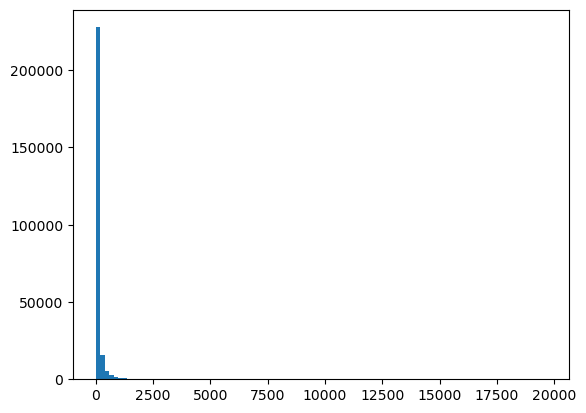

In [8]:
counts, bins, patches = plt.hist(df_fraud_eda['Amount'], bins=100)
bins

array([  260.08  ,   454.0445,   648.009 ,   841.9735,  1035.938 ,
        1229.9025,  1423.867 ,  1617.8315,  1811.796 ,  2005.7605,
        2199.725 ,  2393.6895,  2587.654 ,  2781.6185,  2975.583 ,
        3169.5475,  3363.512 ,  3557.4765,  3751.441 ,  3945.4055,
        4139.37  ,  4333.3345,  4527.299 ,  4721.2635,  4915.228 ,
        5109.1925,  5303.157 ,  5497.1215,  5691.086 ,  5885.0505,
        6079.015 ,  6272.9795,  6466.944 ,  6660.9085,  6854.873 ,
        7048.8375,  7242.802 ,  7436.7665,  7630.731 ,  7824.6955,
        8018.66  ,  8212.6245,  8406.589 ,  8600.5535,  8794.518 ,
        8988.4825,  9182.447 ,  9376.4115,  9570.376 ,  9764.3405,
        9958.305 , 10152.2695, 10346.234 , 10540.1985, 10734.163 ,
       10928.1275, 11122.092 , 11316.0565, 11510.021 , 11703.9855,
       11897.95  , 12091.9145, 12285.879 , 12479.8435, 12673.808 ,
       12867.7725, 13061.737 , 13255.7015, 13449.666 , 13643.6305,
       13837.595 , 14031.5595, 14225.524 , 14419.4885, 14613.4

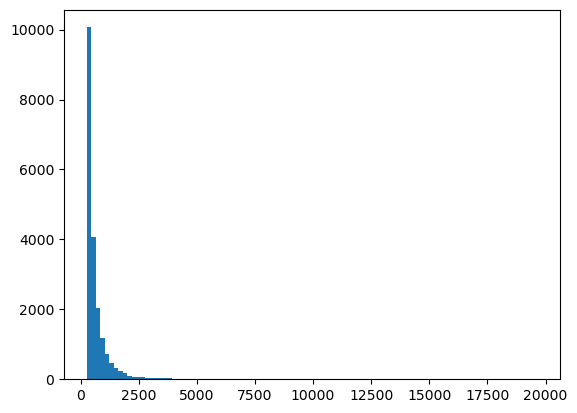

In [9]:
counts2, bins2, patches2 = plt.hist(df_fraud_eda[df_fraud_eda['Amount'] > 260]['Amount'], bins=100)
bins2

Hasil array diatas menunjukan representasi dari histogram yang dibuat. Secara kasat mata, dapat dilihat satu bins yang menjulang sangat tinggi, dimana bins tersebut berada di rentang 0-260 berdasarkan array variable bins.

Selanjutnya dibedah lebih dalam diperkirakan untuk histogram yang tampak pada level kedua berada pada rentang 261 - 2000.

Terakhir, visualisasi histogram dianggap sudah tidak terlihat meskipun ada datanya pada titik > 2000

# Separate The Data

In [10]:
df_bucket_1 = df_fraud_eda.copy()
df_bucket_2 = df_fraud_eda.copy()
df_bucket_3 = df_fraud_eda.copy()

In [11]:
'''
Dasar pengambilan rentang disesuaikan dengan kondisi array data pembentuk bins histogram.

aturannya simpel, diambil yang menjulang tinggi yakni bins 1, lalu perkiraan rentang bins yang masih terlihat pada grafik, 
dan bins yang sudah tidak terlihat pada grafik.
'''

df_bucket_1 = df_bucket_1[(df_bucket_1['Amount'] >= 0) & (df_bucket_1['Amount'] < 260)]
df_bucket_2 = df_bucket_2[(df_bucket_2['Amount'] >= 261) & (df_bucket_2['Amount'] < 2001)]
df_bucket_3 = df_bucket_3[df_bucket_3['Amount'] >= 2001]

# Q1 : Dimanakah rentang transaksi yang memiliki fraud rate terbesar?

In [12]:
check_bucket_1 = pd.DataFrame(columns=['Class', 'Fraud_Rate'])
check_bucket_2 = pd.DataFrame(columns=['Class', 'Fraud_Rate'])
check_bucket_3 = pd.DataFrame(columns=['Class', 'Fraud_Rate'])

check_bucket_1['Class'] = df_bucket_1.groupby('Class')['Class'].count()
check_bucket_2['Class'] = df_bucket_2.groupby('Class')['Class'].count()
check_bucket_3['Class'] = df_bucket_3.groupby('Class')['Class'].count()

In [13]:
total_rows_data = 283726
convert_to_percentage = 100

check_bucket_1.iloc[0, 1] = ((check_bucket_1.iloc[0, 0] / total_rows_data) * convert_to_percentage).round(4) 
check_bucket_1.iloc[1, 1] = ((check_bucket_1.iloc[0, 1] / total_rows_data) * convert_to_percentage).round(4)

check_bucket_2.iloc[0, 1] = ((check_bucket_2.iloc[0, 0] / total_rows_data) * convert_to_percentage).round(4) 
check_bucket_2.iloc[1, 1] = ((check_bucket_2.iloc[0, 1] / total_rows_data) * convert_to_percentage).round(4)

check_bucket_3.iloc[0, 1] = ((check_bucket_3.iloc[0, 0] / total_rows_data) * convert_to_percentage).round(4) 
check_bucket_3.iloc[1, 1] = ((check_bucket_3.iloc[0, 1] / total_rows_data) * convert_to_percentage).round(4)

In [14]:
print(f'Fraud rate untuk rentang 0 - 260 \t: {check_bucket_1.loc[1, "Fraud_Rate"]*100}%')
print(f'Fraud rate untuk rentang 261 - 2000 \t: {check_bucket_2.loc[1, "Fraud_Rate"]*100}%')
print(f'Fraud rate untuk rentang di atas 2000 \t: {check_bucket_3.loc[1, "Fraud_Rate"]*100}%')

Fraud rate untuk rentang 0 - 260 	: 2.92%
Fraud rate untuk rentang 261 - 2000 	: 0.24%
Fraud rate untuk rentang di atas 2000 	: 0.01%


## FE1 : Kategori Rentang Jumlah Transaksi

In [15]:
df_fraud_FE = df_fraud_eda.copy()

In [16]:
df_fraud_FE['Amount_Bucket'] = np.where(df_fraud_eda['Amount'] < 260, '< 260',
                                        np.where(df_fraud_eda['Amount'] > 2000, '> 2000', '261 - 2000'))

## SUMMARY 

Q1 : Dimanakah rentang transaksi yang memiliki fraud rate terbesar? \
A1 : Ada di bucket 1 dengan rentang transaksi 0 - 260 \
\
Akan dibuat Feature Engineering bucket untuk mengelompokkan kategori transaksi apakah transaksi kecil, menengah, atau besar.

# Q2 : Apakah ada pola selisih waktu saat terjadi fraud only dari keseluruhan kasus fraud?

Hipotesisnya adalah siapa tau yang melakukan fraud bekerja sama menentukan pola waktu dari aksi fraud 1 ke aksi fraud yang lain. 

Contoh kita akan melakukan fraud tiap 1 jam sekali.

In [17]:
# Filter Fraud only

pattern_b1_fraud = df_bucket_1[df_bucket_1['Class'] == 1][['Time', 'Amount']]
pattern_b2_fraud = df_bucket_2[df_bucket_2['Class'] == 1][['Time', 'Amount']]
pattern_b3_fraud = df_bucket_3[df_bucket_3['Class'] == 1][['Time', 'Amount']]

In [18]:
pattern_time_b1_fraud = pattern_b1_fraud.copy()
pattern_time_b2_fraud = pattern_b2_fraud.copy()
pattern_time_b3_fraud = pattern_b3_fraud.copy()

In [19]:
# Kolom Pengurang untuk cari Delta Time

pattern_time_b1_fraud['Time_before'] = pattern_time_b1_fraud['Time'].shift(1).fillna(0)
pattern_time_b2_fraud['Time_before'] = pattern_time_b2_fraud['Time'].shift(1).fillna(0)
pattern_time_b3_fraud['Time_before'] = pattern_time_b3_fraud['Time'].shift(1).fillna(0)

In [20]:
# Ini yang akan dianalisa apakah ada pola atau tidak

pattern_time_b1_fraud['Delta_Time'] = pattern_time_b1_fraud['Time'] - pattern_time_b1_fraud['Time_before']
pattern_time_b2_fraud['Delta_Time'] = pattern_time_b2_fraud['Time'] - pattern_time_b2_fraud['Time_before']
pattern_time_b3_fraud['Delta_Time'] = pattern_time_b3_fraud['Time'] - pattern_time_b3_fraud['Time_before']

In [21]:
# Reset index untuk line chart

pattern_time_b1_fraud = pattern_time_b1_fraud.reset_index(drop=True)
pattern_time_b2_fraud = pattern_time_b2_fraud.reset_index(drop=True)
pattern_time_b3_fraud = pattern_time_b3_fraud.reset_index(drop=True)

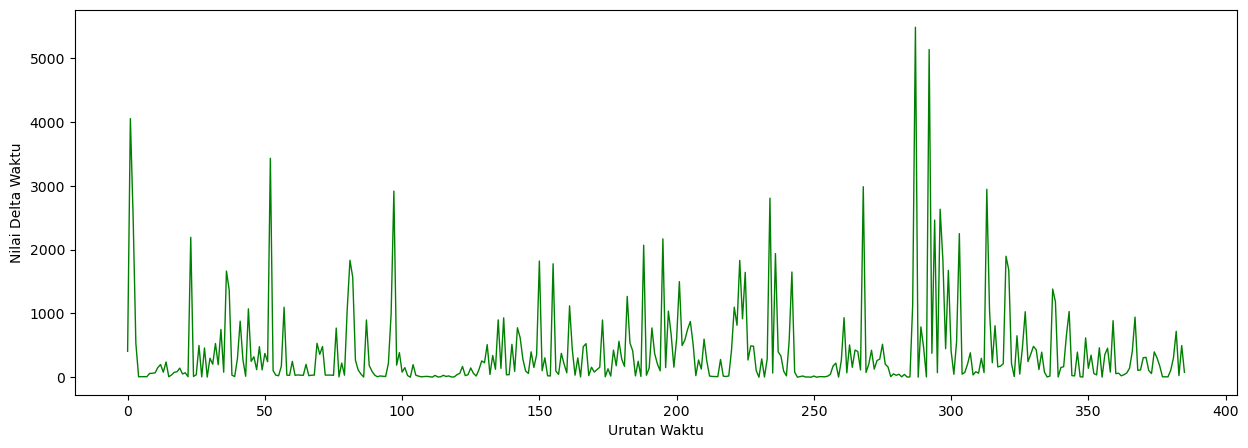

In [22]:
plt.figure(figsize = (15, 5)) # -> lebar 10 inci tinggi 4 inci
plt.plot(pattern_time_b1_fraud.index, pattern_time_b1_fraud['Delta_Time'], color = 'green', linewidth = 1)

plt.xlabel('Urutan Waktu')
plt.ylabel('Nilai Delta Waktu')
plt.show()

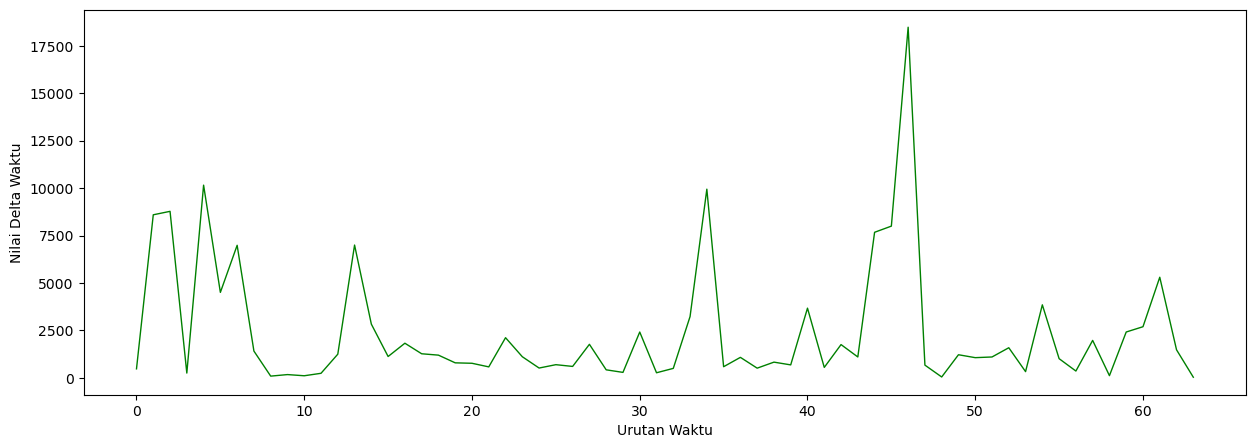

In [23]:
plt.figure(figsize = (15, 5)) # -> lebar 10 inci tinggi 4 inci
plt.plot(pattern_time_b2_fraud.index, pattern_time_b2_fraud['Delta_Time'], color = 'green', linewidth = 1)

plt.xlabel('Urutan Waktu')
plt.ylabel('Nilai Delta Waktu')
plt.show()

## SUMMARY 

Q2 : Apakah ada pola selisih waktu saat terjadi fraud only?\
A2 : Ga ada ternyata, ekspektasi nya padahal kayak grafik musik bikin pola berulang

# Q4 : Apakah ada pola selisih waktu antara fraud dengan baris sebelumnya?

In [24]:
only_fraud = df_fraud_eda[df_fraud_eda['Class'] == 1]
indeks_only_fraud = only_fraud.index.to_list()
indeks_only_fraud[:5] # -> simplified

[534, 616, 4886, 6072, 6293]

In [25]:
indeks_before_fraud = [indeks-1 for indeks in indeks_only_fraud]
indeks_before_fraud[:5] # -> simplified

[533, 615, 4885, 6071, 6292]

In [26]:
indeks_checked = sorted(indeks_only_fraud + indeks_before_fraud)
indeks_checked[:5] # -> simplified

[533, 534, 615, 616, 4885]

In [27]:
df_pattern_fraud = df_fraud_eda.loc[indeks_checked][['Time', 'Amount']]
df_pattern_fraud.head(5)

,Time,Amount
533,406.0,1.98
534,406.0,0.00
615,472.0,17.57
616,472.0,529.00
4885,4462.0,18.98


In [28]:
df_pattern_fraud['Time_Before'] = df_pattern_fraud['Time'].shift(1)
df_pattern_fraud = df_pattern_fraud[['Time', 'Time_Before', 'Amount']]
df_pattern_fraud.head(5)

,Time,Time_Before,Amount
533,406.0,NaN,1.98
534,406.0,406.0,0.00
615,472.0,406.0,17.57
616,472.0,472.0,529.00
4885,4462.0,472.0,18.98


In [29]:
df_pattern_fraud['Amount_Before'] = df_pattern_fraud['Amount'].shift(1)
df_pattern_fraud.head(5)

,Time,Time_Before,Amount,Amount_Before
533,406.0,NaN,1.98,NaN
534,406.0,406.0,0.00,1.98
615,472.0,406.0,17.57,0.00
616,472.0,472.0,529.00,17.57
4885,4462.0,472.0,18.98,529.00


In [30]:
df_pattern_fraud = df_pattern_fraud.fillna(0)

In [31]:
df_pattern_fraud

,Time,Time_Before,Amount,Amount_Before
533,406.0,0.0,1.98,0.00
534,406.0,406.0,0.00,1.98
615,472.0,406.0,17.57,0.00
616,472.0,472.0,529.00,17.57
4885,4462.0,472.0,18.98,529.00
...,...,...,...,...
253455,156710.0,156710.0,7.59,39.43
254456,157207.0,156710.0,20.00,7.59
254457,157207.0,157207.0,4.97,20.00
254606,157283.0,157207.0,0.76,4.97


In [32]:
# Cek ada kasus time yang > Time After ga (harusnya ga ada sih)

df_pattern_fraud[df_pattern_fraud['Time_Before'] > df_pattern_fraud['Time']]

,Time,Time_Before,Amount,Amount_Before


In [33]:
# Sip maka valid pakai rumus Time After - Time untuk cek pattern

df_pattern_fraud['Delta_Time'] = df_pattern_fraud['Time'] - df_pattern_fraud['Time_Before']
df_pattern_fraud.head(5)

,Time,Time_Before,Amount,Amount_Before,Delta_Time
533,406.0,0.0,1.98,0.00,406.0
534,406.0,406.0,0.00,1.98,0.0
615,472.0,406.0,17.57,0.00,66.0
616,472.0,472.0,529.00,17.57,0.0
4885,4462.0,472.0,18.98,529.00,3990.0


In [34]:
index_fraud_event_processed = [index for index in df_pattern_fraud.index.to_list() if index % 2 == 0]

In [35]:
df_pattern_fraud['Delta_Time'].value_counts()

Delta_Time
0.0      224
1.0      147
2.0       47
3.0       21
5.0       19
        ... 
57.0       1
396.0      1
176.0      1
107.0      1
719.0      1
Name: count, Length: 287, dtype: int64

In [36]:
# Secara kasat mata, top 3 selisih waktu terjadi nya fraud dengan transaksi asli adalah 6 detik, maka kita akan coba buat bucketing sederhana

df_pattern_fraud['Fraud_Delta_Time_Based'] = np.where(
                                    df_pattern_fraud['Delta_Time'] < 16, '<= 15', '>15')

<Axes: ylabel='Fraud_Delta_Time_Based'>

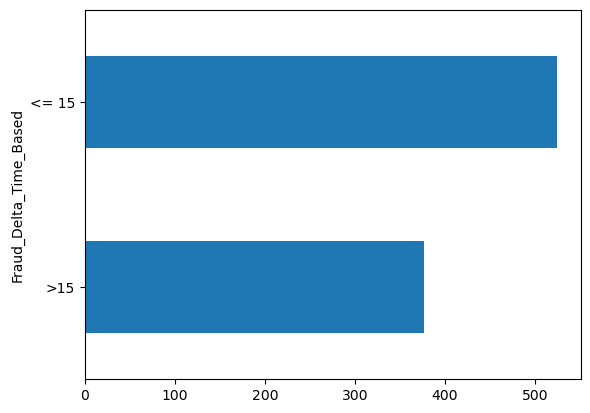

In [37]:
df_pattern_fraud['Fraud_Delta_Time_Based'].value_counts(ascending=True).plot(kind='barh')

In [38]:
df_pattern_fraud['Fraud_Delta_Time_Based'].value_counts()

Fraud_Delta_Time_Based
<= 15    525
>15      377
Name: count, dtype: int64

## FE2 : Delta_Time Dari Masing Masing Transaksi

In [39]:
df_fraud_FE.head(2)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Amount_Bucket
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0,< 260
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0,< 260


In [40]:
delta_time_feature = df_fraud_FE[['Time', 'Amount']]
delta_time_feature['Time_Before'] = df_fraud_FE['Time'].shift(1).fillna(0)
delta_time_feature['Delta_Time'] = delta_time_feature['Time'] - delta_time_feature['Time_Before']

C:\Users\Alfi Ahmad Fauzi\AppData\Local\Temp\ipykernel_12728\4245487013.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  delta_time_feature['Time_Before'] = df_fraud_FE['Time'].shift(1).fillna(0)
C:\Users\Alfi Ahmad Fauzi\AppData\Local\Temp\ipykernel_12728\4245487013.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  delta_time_feature['Delta_Time'] = delta_time_feature['Time'] - delta_time_feature['Time_Before']


In [41]:
delta_time_feature = delta_time_feature[['Time', 'Time_Before', 'Delta_Time']]

In [42]:
delta_time_feature['Delta_Time_Bucket'] = np.where(delta_time_feature['Delta_Time'] < 16, '<= 15', '>15')

In [43]:
delta_time_feature.head(5)

,Time,Time_Before,Delta_Time,Delta_Time_Bucket
0,0.0,0.0,0.0,<= 15
1,0.0,0.0,0.0,<= 15
2,1.0,0.0,1.0,<= 15
3,1.0,1.0,0.0,<= 15
4,2.0,1.0,1.0,<= 15


In [44]:
df_fraud_FE = df_fraud_FE.copy()

In [45]:
df_fraud_FE = df_fraud_FE.merge(delta_time_feature[['Time', 'Delta_Time_Bucket']], on='Time', how='inner')

In [46]:
df_fraud_FE.head(5)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V23,V24,V25,V26,V27,V28,Amount,Class,Amount_Bucket,Delta_Time_Bucket
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0,< 260,<= 15
1,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0,< 260,<= 15
2,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0,< 260,<= 15
3,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0,< 260,<= 15
4,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0,261 - 2000,<= 15


## SUMMARY 

Q4 : Apakah ada pola selisih waktu antara fraud dengan baris sebelumnya?\
A4 : Ada, transaksi fraud banyak terjadi di rentang 0 - 15 detik dari transaksi yang sudah terjadi.

## Q4.1 : Jika Q4 valid apakah pola ini valid, apakah ini juga didukung dengan kondisi yang non fraud?

In [47]:
# kita harus filter dulu indeks yang pair non_fraud lalu setelahnya fraud.

df_pattern_non_fraud = df_fraud_eda[~df_fraud_eda.index.isin(index_fraud_event_processed)][['Time', 'Amount']]
df_pattern_non_fraud.head(5)

,Time,Amount
0,0.0,149.62
1,0.0,2.69
2,1.0,378.66
3,1.0,123.50
4,2.0,69.99


In [48]:
df_pattern_non_fraud['Time_Before'] = df_pattern_non_fraud['Time'].shift(1).fillna(0)
df_pattern_non_fraud.head(5)

,Time,Amount,Time_Before
0,0.0,149.62,0.0
1,0.0,2.69,0.0
2,1.0,378.66,0.0
3,1.0,123.50,1.0
4,2.0,69.99,1.0


In [49]:
df_pattern_non_fraud['Amount_Before'] = df_pattern_non_fraud['Amount'].shift(1).fillna(0)
df_pattern_non_fraud.head(5)

,Time,Amount,Time_Before,Amount_Before
0,0.0,149.62,0.0,0.00
1,0.0,2.69,0.0,149.62
2,1.0,378.66,0.0,2.69
3,1.0,123.50,1.0,378.66
4,2.0,69.99,1.0,123.50


In [50]:
# bikin serupa dengan yang fraud

df_pattern_non_fraud['Delta_Time'] = df_pattern_non_fraud['Time_Before'] - df_pattern_non_fraud['Time']

In [51]:
df_pattern_non_fraud['Delta_Time'].value_counts()

Delta_Time
 0.0     143099
-1.0      89323
-2.0      13944
-3.0       3847
-4.0       1751
-5.0        945
-6.0        613
-7.0        375
-8.0        308
-9.0        200
-10.0       138
-11.0        90
-12.0        59
-13.0        57
-14.0        36
-15.0        26
-16.0        24
-19.0        14
-17.0        14
-18.0         9
-21.0         6
-20.0         6
-22.0         5
-26.0         4
-32.0         4
-28.0         3
-24.0         2
-25.0         2
-27.0         1
-23.0         1
Name: count, dtype: int64

In [52]:
df_pattern_non_fraud['Non_Fraud_Delta_Time_Based'] = np.where(df_pattern_non_fraud['Delta_Time'] < 16, '<= 15','> 15')

In [53]:
df_pattern_non_fraud.head(5)

,Time,Amount,Time_Before,Amount_Before,Delta_Time,Non_Fraud_Delta_Time_Based
0,0.0,149.62,0.0,0.00,0.0,<= 15
1,0.0,2.69,0.0,149.62,0.0,<= 15
2,1.0,378.66,0.0,2.69,-1.0,<= 15
3,1.0,123.50,1.0,378.66,0.0,<= 15
4,2.0,69.99,1.0,123.50,-1.0,<= 15


In [54]:
# lihat perbandingan antara kedua pattern

fraud = df_pattern_fraud['Fraud_Delta_Time_Based'].value_counts(ascending=True)
non_fraud = df_pattern_non_fraud['Non_Fraud_Delta_Time_Based'].value_counts(ascending=True)

df_compare = pd.DataFrame({
    'fraud' : fraud,
    'non_fraud' : non_fraud,
})

<Axes: >

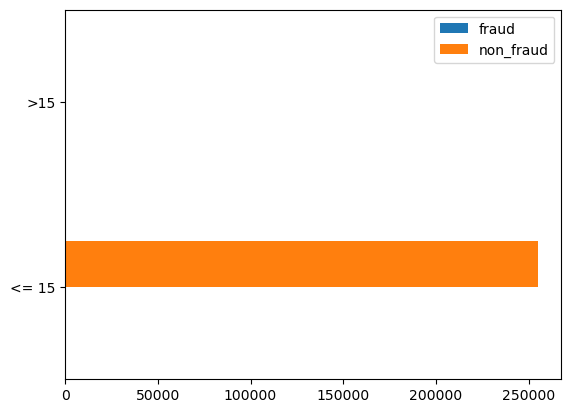

In [55]:
df_compare.plot(kind='barh')

### SUMMARY 

Q4.1 : Jika Q4 valid apakah pola ini valid, apakah ini juga didukung dengan kondisi yang non fraud?\
A4.1 : Pelaku melakukan aksi memang di semesta waktu transaksi terbanyak.

## FINAL SUMMARY Q4

Actionable : dilakukan feature engineering untuk penentuan delta time karena memang ada pola untuk fraud walaupun pola yang sama terjadi di non-fraud (transaksi memang banyak terjadi di selisih waktu 0 - 15 detik)

# Q5 : Apakah ada pola selisih Amount antara fraud dengan baris sebelumnya?

In [56]:
df_pattern_fraud.head(5)

,Time,Time_Before,Amount,Amount_Before,Delta_Time,Fraud_Delta_Time_Based
533,406.0,0.0,1.98,0.00,406.0,>15
534,406.0,406.0,0.00,1.98,0.0,<= 15
615,472.0,406.0,17.57,0.00,66.0,>15
616,472.0,472.0,529.00,17.57,0.0,<= 15
4885,4462.0,472.0,18.98,529.00,3990.0,>15


In [57]:
df_pattern_fraud['Percent_Fraud_Amount'] = ((df_pattern_fraud['Amount'] / df_pattern_fraud['Amount_Before']) * 100).round(2)

In [58]:
# Yang perlu di highlight yang hasilnya inf, nan. Sisanya kita coba cek buat bucketing persentase 0, 1 - 50, 51 - 100, dan diatas 100

df_pattern_fraud['Percent_Fraud_Amount'].unique()

array([          inf, 0.0000000e+00, 3.0108100e+03, 3.5900000e+00,
       1.2641200e+03, 1.2500000e+01, 1.9673000e+02, 3.3050000e+01,
       5.1300000e+00, 1.1140200e+05, 9.0000000e-02, 7.4900000e+02,
       1.3350000e+01, 2.9990000e+03, 3.3300000e+00, 9.9900000e+02,
       1.0010000e+01, 3.6000000e+03, 2.7800000e+00, 2.6800000e+02,
       3.7310000e+01, 4.5000000e+03, 2.2200000e+00, 5.0000000e+02,
       2.0000000e+01, 3.5990000e+03, 6.6000000e+03, 1.5200000e+00,
       1.0710000e+04, 9.3000000e-01, 7.6000000e+01, 1.3158000e+02,
       1.2750000e+03, 7.8400000e+00, 1.0000000e+02, 9.9990000e+03,
       1.0000000e+00, 1.7020000e+03, 6.4600000e+00, 4.5455000e+02,
       1.8114910e+04, 2.1600000e+00, 2.5600000e+00, 6.2400000e+04,
       1.6000000e-01, 3.3000000e+02, 3.0300000e+01, 4.5150000e+04,
       2.2000000e-01, 1.6300000e+04, 1.5348500e+03, 4.0080000e+01,
       1.4750400e+03, 5.9000000e+00, 9.4300000e+00, 1.1500000e+04,
       8.7000000e-01, 6.3400000e+02, 1.5770000e+01, 3.5870000e

In [59]:
'''
0        = 0%
1 - 50   = rentang 1 - 50%
51 - 100 = rentang 51 - 100%
> 100    = diatas 100%
-99      = infinite
-98      = nan
'''
df_pattern_fraud['Bucket_Percent_Fraud_Amount'] = np.where(
                                                    df_pattern_fraud['Percent_Fraud_Amount'] == 0, '0%',
                                                        np.where(
                                                            (df_pattern_fraud['Percent_Fraud_Amount'] > 0) & (df_pattern_fraud['Percent_Fraud_Amount'] <= 50), '1-50%',
                                                                np.where(
                                                                   (df_pattern_fraud['Percent_Fraud_Amount'] > 50) & (df_pattern_fraud['Percent_Fraud_Amount'] <= 100), '51-100%',
                                                                        np.where(
                                                                            (df_pattern_fraud['Percent_Fraud_Amount'] > 100), '> 100%',
                                                                                np.where(
                                                                                    df_pattern_fraud['Percent_Fraud_Amount'] == np.inf, '-99', '-98'
                                                                                )))))

In [60]:
df_pattern_fraud[['Fraud_Delta_Time_Based', 'Bucket_Percent_Fraud_Amount']].value_counts()

Fraud_Delta_Time_Based  Bucket_Percent_Fraud_Amount
<= 15                   > 100%                         242
                        1-50%                          203
>15                     > 100%                         200
                        1-50%                          144
<= 15                   51-100%                         52
>15                     51-100%                         30
<= 15                   0%                              23
                        -98                              5
>15                     0%                               3
Name: count, dtype: int64

In [61]:
df_pattern_fraud

,Time,Time_Before,Amount,Amount_Before,Delta_Time,Fraud_Delta_Time_Based,Percent_Fraud_Amount,Bucket_Percent_Fraud_Amount
533,406.0,0.0,1.98,0.00,406.0,>15,inf,> 100%
534,406.0,406.0,0.00,1.98,0.0,<= 15,0.00,0%
615,472.0,406.0,17.57,0.00,66.0,>15,inf,> 100%
616,472.0,472.0,529.00,17.57,0.0,<= 15,3010.81,> 100%
4885,4462.0,472.0,18.98,529.00,3990.0,>15,3.59,1-50%
...,...,...,...,...,...,...,...,...
253455,156710.0,156710.0,7.59,39.43,0.0,<= 15,19.25,1-50%
254456,157207.0,156710.0,20.00,7.59,497.0,>15,263.50,> 100%
254457,157207.0,157207.0,4.97,20.00,0.0,<= 15,24.85,1-50%
254606,157283.0,157207.0,0.76,4.97,76.0,>15,15.29,1-50%


Hipotesa tidak valid, hal ini dikarenakan akan berpotensi mengganggu transaksi nyata, jika ini diterapkan maka transaksi akan terjadi dengan jeda waktu 15 detik + total percobaan transaksi pada orang yang sama yang dianggap fraud karena nominal nya masuk ke bucket yang dianggap fraud berdasarkan transaksi orang sebelumnya.

# Q6 : Dari tiap tiap feature yang "dianggap penting", bagaimana sebaran fraud di outlier masing masing feature?

In [62]:
scaler = StandardScaler()

df_fraud_eda['Amount'] = scaler.fit_transform(df_fraud_eda[['Amount']])

joblib.dump(scaler, '../Output/Model/model_standard_scaler.pkl')

['../Output/Model/model_standard_scaler.pkl']

In [63]:
only_fraud = df_fraud_eda[df_fraud_eda['Class'] == 1]

In [64]:
only_fraud_reduced = only_fraud[['V17', 'V14', 'V10', 'V12', 'V11', 'V16', 'V3', 'V4', 'V9', 'V18', 'V7', 'V1', 'V26', 'Amount', 'V24', 'V22', 'V8']]

## Analisa Feature Penting

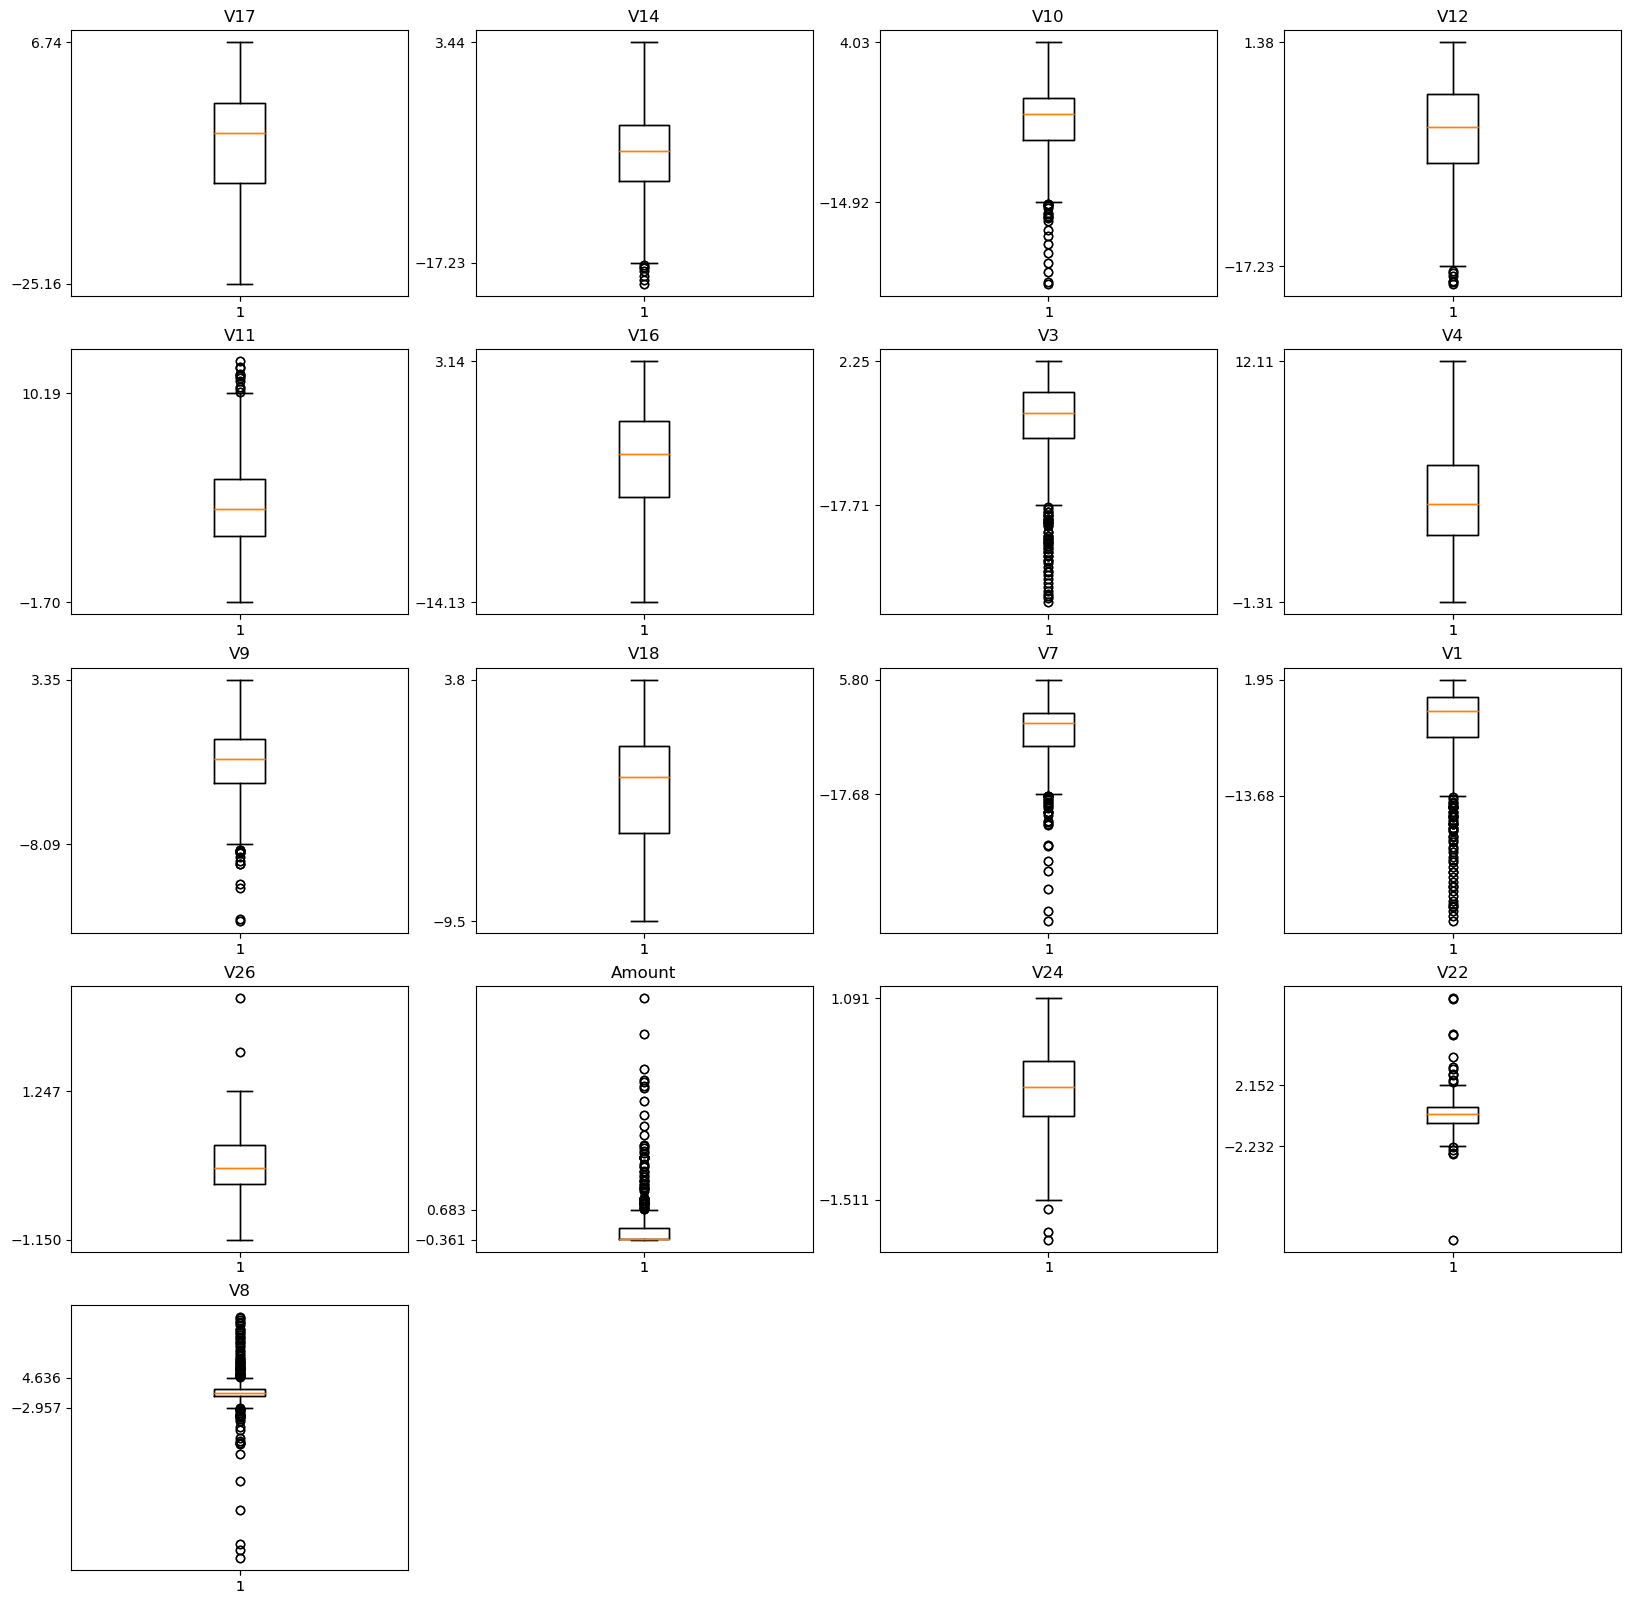

In [65]:
# Boxplot

feature = only_fraud_reduced.columns
index_feature = 0

fig, axes = plt.subplots(nrows=5, ncols=4, figsize=(20, 20))

for row in range(0,5):
    for col in range(0,4):

        if index_feature >= len(feature):
            axes[row, col].axis('off')
            continue
        axes[row, col].boxplot(only_fraud_reduced[feature[index_feature]])
        axes[row, col].set_title(feature[index_feature])

        ticks = axes[row, col].boxplot(only_fraud_reduced[feature[index_feature]])
        lowest_tick = ticks['whiskers'][0].get_ydata()[1]
        highest_tick = ticks['whiskers'][1].get_ydata()[1]

        axes[row, col].set_yticks([lowest_tick, highest_tick])

        index_feature += 1
        
plt.show()

## FE3 : Bucket Masing Masing Feature

In [66]:
df_fraud_FE = df_fraud_FE.copy()

In [67]:
df_fraud_FE['Bucket_V14'] = np.where(df_fraud_FE['V14'] < -17.23, '< -17.23', '>= -17.23')

In [68]:
df_fraud_FE['Bucket_V10'] = np.where(df_fraud_FE['V10'] < -14.92, '< -14.92', '>= -14.92')

In [69]:
df_fraud_FE['Bucket_V12'] = np.where(df_fraud_FE['V12'] < -17.23, '< -17.23', '>= -17.23')

In [70]:
df_fraud_FE['Bucket_V11'] = np.where(df_fraud_FE['V11'] > 10.19, '> 10.19', '<= 10.19')

In [71]:
df_fraud_FE['Bucket_V3'] = np.where(df_fraud_FE['V3'] < -17.71, '< -17.71', '>= -17.71')

In [72]:
df_fraud_FE['Bucket_V9'] = np.where(df_fraud_FE['V9'] < -8.09, '< -8.09', '>= -8.09')

In [73]:
df_fraud_FE['Bucket_V7'] = np.where(df_fraud_FE['V7'] < -17.68, '< -17.68', '>= -17.68')

In [74]:
df_fraud_FE['Bucket_V1'] = np.where(df_fraud_FE['V1'] < -13.68, '< -13.68', '>= -13.68')

In [75]:
df_fraud_FE['Bucket_V26'] = np.where(df_fraud_FE['V26'] > 1.247, '> 1.247', '<= 1.247')

In [76]:
df_fraud_FE['Bucket_Amount'] = np.where(df_fraud_FE['Amount'] > 0.683, '> 0.683', '<= 0.683')

In [77]:
df_fraud_FE['Bucket_V24'] = np.where(df_fraud_FE['V24'] < -1.511, '< -1.511', '>= -1.511')

In [80]:
df_fraud_FE['Bucket_V22'] = np.where(df_fraud_FE['V22'] < -2.232, '< -2.232', 
                                     np.where(df_fraud_FE['V22'] > 2.152, '> 2.152', '-2.232 s.d 2.152'))

In [81]:
df_fraud_FE['Bucket_V8'] = np.where(df_fraud_FE['V8'] < -2.957, '< -2.957', 
                                     np.where(df_fraud_FE['V22'] > 4.636, '> 4.636', '-2.957 s.d 4.636'))

# Export Data Hasil Feature Enginering dan EDA

In [83]:
df_fraud_FE = df_fraud_FE.drop_duplicates()

In [84]:
df_fraud_FE.to_csv('../Data/result/03_Exploratory_Data_Analysis_Train.csv', index=False)